In [ ]:
# Persiapan tambahan notebook.
import sys
import time
import hashlib
import urllib.request
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})
try:
    from threadpoolctl import threadpool_limits
    blas_limiter = threadpool_limits(limits=1)
    print('BLAS dibatasi ke satu thread untuk eksperimen NumPy ini.')
except ImportError:
    print('threadpoolctl tidak tersedia; memakai pengaturan BLAS lingkungan.')
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Matplotlib:', matplotlib.__version__)

BLAS dibatasi ke satu thread untuk eksperimen NumPy ini.
Python: 3.13.16
NumPy: 2.1.3
Matplotlib: 3.10.0


## 2. Ringkasan Chapter 9

Fungsi aktivasi mengubah weighted sum sebuah layer menjadi activation. Pada hidden layer, fungsi nonlinear memungkinkan jaringan membangun representasi yang tidak dapat diperoleh hanya dari rangkaian perkalian matriks linear. Pada output layer, pemilihan aktivasi perlu sesuai dengan jenis target.

Sigmoid memetakan nilai real ke rentang 0-1. Tanh memetakan ke rentang -1 sampai 1 dan memiliki output yang berpusat di nol. Keduanya dapat mengalami saturation: pada input dengan magnitudo besar, turunan sangat kecil sehingga sinyal gradien melemah. ReLU memberi contoh lain, yaitu unit aktif atau tidak aktif dengan kemiringan lokal 1 atau 0.

Untuk klasifikasi satu digit dari sepuluh kelas, softmax mengubah sepuluh logit menjadi distribusi categorical dengan jumlah probabilitas satu. Sigmoid sesuai ketika tiap label mempunyai jawaban yes/no tersendiri. Menghasilkan angka di rentang 0-1 atau menjumlahkannya menjadi satu belum membuktikan bahwa prediksi terkalibrasi dengan baik.

Menambah aktivasi pada forward juga mengubah backward. Delta perlu dikalikan dengan turunan lokal; khusus softmax, semua output saling terkait melalui Jacobian. Jika softmax dipasangkan dengan categorical cross-entropy, gradien terhadap logit menyederhana menjadi prediksi dikurangi target, dengan pembagian batch sekali untuk loss rata-rata.

Bagian akhir mengganti hidden activation MNIST menjadi tanh dan output menjadi softmax. Buku memperkecil rentang awal bobot input-hidden serta menyesuaikan learning rate. Notebook mereproduksi listing lengkap, menguji checkpoint sumber, dan memberi pendalaman tentang gradien, dropout, serta interpretasi hasil.

**Rujukan utama:** Trask (2019), hlm. 161-175.

## 3. Peta subbab dan cakupan

| Subbab buku | Halaman cetak | Pengerjaan dalam notebook |
| --- | --- | --- |
| What is an activation function? | 162-164 | Domain, continuity, monotonicity, nonlinearity, dan efisiensi |
| Standard hidden-layer activation functions | 165 | Sigmoid, tanh, kurva, turunan, dan saturation |
| Standard output layer activation functions | 166-167 | Identity, sigmoid, dan softmax sesuai jenis target |
| The core issue: Inputs have similarity | 168 | Shared feature dan kompetisi kelas; batas interpretasi |
| Softmax computation | 169 | Eksponensial, normalisasi, shift stabil, dan temperature |
| Activation installation instructions | 170-171 | Reproduksi forward ReLU serta potongan delta sumber |
| Multiplying delta by the slope | 172 | Aturan rantai dan sensitivitas lokal |
| Converting output to slope (derivative) | 173 | Rumus yang benar, Jacobian, dan catatan tabel sumber |
| Upgrading the MNIST network | 174-175 | Inisialisasi, reproduksi 300 epoch, dan analisis hasil |

Cross-entropy secara rinci, stable softmax, validation tambahan, pemeriksaan gradien, serta trainer dengan cache dan scaling yang konsisten adalah pendalaman. Cuplikan kode berulang dibahas bersama program lengkap agar tidak menjadi sel yang gagal karena variabel belum didefinisikan.

## 4. Fungsi aktivasi dan arti nonlinearity

Untuk sebuah neuron:

$$z_j=\sum_i x_iw_{ij}+b_j,\qquad h_j=f(z_j).$$

$z_j$ disebut **preactivation**: input ke fungsi aktivasi. $h_j$ adalah hasil aktivasi. Preactivation hidden layer bukan nama lain untuk input mentah jaringan. Pada kode buku bab ini tidak ada bias, sehingga $b_j=0$.

Buku memperkenalkan empat sifat: terdefinisi untuk seluruh input, continuous, monotonic, nonlinear, dan dapat dihitung efisien (dua sifat pertama dibahas dalam satu constraint). Untuk jaringan yang dioptimalkan dengan gradien, fungsi dengan turunan yang dapat dipakai hampir di mana-mana sangat membantu. ReLU tidak terdiferensiasi di nol; implementasi dapat memilih subgradient nol di titik itu.

Monotonicity adalah pedoman, bukan syarat wajib. **Monotonic tidak selalu berarti one-to-one:** ReLU konstan pada semua input negatif. Aktivasi monotonic juga tidak membuat optimisasi seluruh jaringan menjadi convex, karena loss tetap bergantung pada komposisi dan interaksi banyak parameter.

Tanpa nonlinearity, dua layer tanpa bias dapat digabung:

$$\hat Y=(XW_{01})W_{12}=X(W_{01}W_{12}).$$

Dengan bias, komposisi transformasi affine tetap affine. Hidden layer linear tambahan tidak menciptakan jenis pemetaan yang lebih luas. Dengan $f$, sensitivitas suatu unit adalah:

$$\frac{\partial h_j}{\partial x_i}=f'(z_j)w_{ij}.$$

Input tertentu dapat mengubah $z_j$ dan $f'(z_j)$, sehingga mengubah sensitivitas unit terhadap semua inputnya. Inilah penjelasan matematis untuk intuisi selective correlation pada buku. Nilai aktivasi negatif pada tanh sendiri tidak otomatis berarti korelasi statistik negatif; kontribusi akhir juga bergantung pada bobot berikutnya.

**Rujukan:** Trask (2019), hlm. 162-165. Catatan one-to-one, subgradient, dan sensitivitas adalah penjelasan matematis tambahan.

In [ ]:
# Pendalaman: layer linear dapat digabung, sedangkan tanh mengubah pemetaan.
X_demo = np.array([[1.0, -0.5], [0.2, 0.8]])
W01_demo = np.array([[0.7, -1.2, 0.4], [-0.3, 0.6, 1.0]])
W12_demo = np.array([[0.5, -0.2], [0.4, 0.9], [-0.8, 0.3]])
linear_two_layers = X_demo @ W01_demo @ W12_demo
linear_collapsed = X_demo @ (W01_demo @ W12_demo)
nonlinear_output = np.tanh(X_demo @ W01_demo) @ W12_demo
assert np.allclose(linear_two_layers, linear_collapsed)
assert not np.allclose(nonlinear_output, linear_collapsed)
print('Dua layer linear:\n', linear_two_layers)
print('Satu matriks gabungan:\n', linear_collapsed)
print('Hidden tanh:\n', nonlinear_output)

Dua layer linear:
 [[-0.095 -1.55 ]
 [-0.658  0.5  ]]
Satu matriks gabungan:
 [[-0.095 -1.55 ]
 [-0.658  0.5  ]]
Hidden tanh:
 [[ 0.06321  -0.982748]
 [-0.520771  0.443806]]


## 5. Sigmoid, tanh, ReLU, dan turunannya

$$\sigma(z)=\frac{1}{1+e^{-z}},\qquad \sigma'(z)=\sigma(z)(1-\sigma(z)).$$

Karena $0<\sigma(z)<1$, turunan maksimum adalah $1/4$ pada $z=0$. Sigmoid pada hidden layer tidak berpusat di nol. Pada input sangat positif atau negatif, activation mendekati batas rentangnya dan turunannya mengecil.

$$\tanh(z)=\frac{e^z-e^{-z}}{e^z+e^{-z}}=2\sigma(2z)-1,\qquad \tanh'(z)=1-\tanh^2(z).$$

Tanh mempunyai $-1<\tanh(z)<1$, output berpusat di nol, dan turunan maksimum 1 pada nol. Tanh masih bisa mengalami saturation. Buku memilih tanh untuk hidden layer pada eksperimen ini; pilihan tersebut bukan jaminan bahwa tanh selalu mengungguli sigmoid atau ReLU pada semua masalah.

$$\operatorname{ReLU}(z)=\max(0,z),\qquad
\operatorname{ReLU}'(z)=\begin{cases}1,&z>0\\0,&z<0.\end{cases}$$

Di $z=0$ dipilih subgradient 0 untuk kode pendalaman. ReLU bersifat piecewise linear tetapi bukan fungsi linear global. Output sigmoid/tanh dapat membulat menjadi batas rentang pada floating point, walaupun secara matematis batas tersebut tidak dicapai untuk input real berhingga.

Menggunakan hasil forward untuk sigmoid/tanh menghindari penghitungan ulang eksponensial. Cache harus menyimpan **hasil aktivasi sebelum operasi lain seperti dropout**. Tidak semua fungsi atau komposisi aktivasi bisa dihitung turunannya hanya dari output akhir yang telah dimodifikasi.

**Rujukan:** Trask (2019), hlm. 165, 171-173. Implementasi stabil dan pemeriksaan berikut adalah pendalaman.

In [ ]:
# Sigmoid dan ReLU untuk penjelasan; stable sigmoid menghindari exp terlalu besar.
def sigmoid_stable(x):
    x = np.asarray(x, dtype=np.float64)
    positive = x >= 0
    result = np.empty_like(x)
    result[positive] = 1 / (1 + np.exp(-x[positive]))
    exp_x = np.exp(x[~positive])
    result[~positive] = exp_x / (1 + exp_x)
    return result

def sigmoid2deriv(output):
    return output * (1 - output)

def relu(x):
    return (x >= 0) * x

# Reproduksi fungsi pada halaman 174, termasuk softmax tanpa shift.
def tanh(x):
    return np.tanh(x)

def tanh2deriv(output):
    return 1 - (output ** 2)

def softmax(x):
    temp = np.exp(x)
    return temp / np.sum(temp, axis=1, keepdims=True)

activation_points = np.array([-6., -2., 0., 2., 6.])
sigmoid_points = sigmoid_stable(activation_points)
tanh_points = tanh(activation_points)
print(' z       sigmoid    sigmoid_deriv    tanh       tanh_deriv')
for z, s, t in zip(activation_points, sigmoid_points, tanh_points):
    print(f'{z:5.1f}    {s:9.6f}    {s*(1-s):13.6f}    {t:9.6f}    {1-t*t:10.6f}')
assert np.allclose(tanh_points, 2 * sigmoid_stable(2*activation_points) - 1)
assert np.all(np.isfinite(sigmoid_stable(np.array([-1000., 1000.]))))

 z       sigmoid    sigmoid_deriv    tanh       tanh_deriv
 -6.0     0.002473         0.002467    -0.999988      0.000025
 -2.0     0.119203         0.104994    -0.964028      0.070651
  0.0     0.500000         0.250000     0.000000      1.000000
  2.0     0.880797         0.104994     0.964028      0.070651
  6.0     0.997527         0.002467     0.999988      0.000025


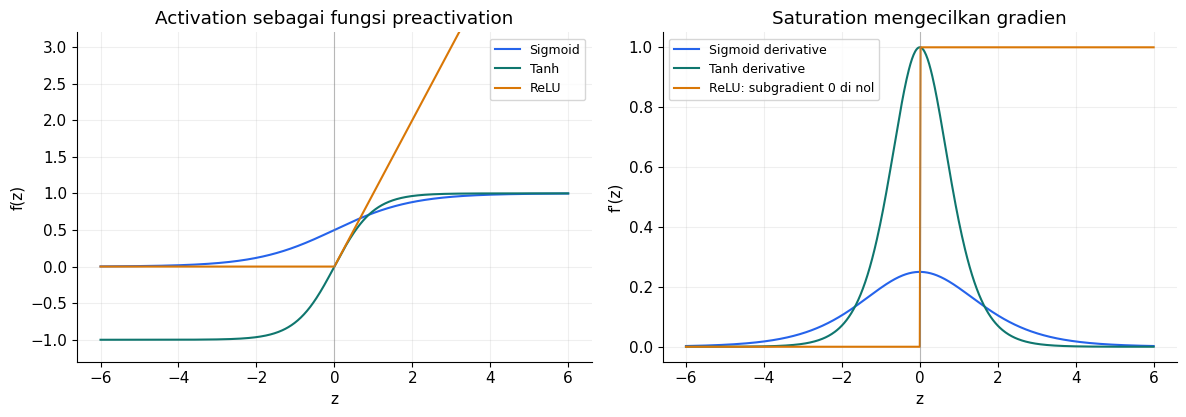

In [ ]:
# Grafik 1: fungsi dan slope lokal, dibuat dari perhitungan kode.
grid = np.linspace(-6, 6, 601)
s_grid, t_grid = sigmoid_stable(grid), tanh(grid)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].plot(grid, s_grid, label='Sigmoid', color='#2563eb')
axes[0].plot(grid, t_grid, label='Tanh', color='#0f766e')
axes[0].plot(grid, relu(grid), label='ReLU', color='#d97706')
axes[0].set(title='Activation sebagai fungsi preactivation', xlabel='z', ylabel='f(z)')
axes[0].set_ylim(-1.3, 3.2)
axes[1].plot(grid, sigmoid2deriv(s_grid), label='Sigmoid derivative', color='#2563eb')
axes[1].plot(grid, tanh2deriv(t_grid), label='Tanh derivative', color='#0f766e')
axes[1].plot(grid, (grid > 0).astype(float), label='ReLU: subgradient 0 di nol', color='#d97706')
axes[1].set(title='Saturation mengecilkan gradien', xlabel='z', ylabel="f'(z)")
for ax in axes:
    ax.axvline(0, color='gray', linewidth=0.8, alpha=0.5)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 6. Memilih output sesuai target

| Jenis target | Output yang sesuai | Interpretasi | Loss yang lazim dipasangkan |
| --- | --- | --- | --- |
| Nilai real tanpa batas, misalnya suhu | Identity: $\hat y=z$ | Prediksi nilai real | Squared error |
| Satu jawaban yes/no | Satu sigmoid | $P(y=1\mid x)$ | Binary cross-entropy |
| Beberapa label yang dapat benar bersamaan | Sigmoid per label | Probabilitas marginal masing-masing label | Binary cross-entropy per label |
| Tepat satu kelas dari beberapa kelas | Softmax satu vektor | Distribusi categorical atas kelas | Categorical cross-entropy |

Pada multi-label, probabilitas tidak harus berjumlah satu. Misalnya, peluang cedera dan kemenangan dapat sama-sama tinggi. Menggunakan sigmoid per label tidak membuktikan bahwa kejadian di dunia nyata independen secara statistik. Sebaliknya, softmax membatasi jumlah probabilitas menjadi satu untuk kelas yang saling eksklusif.

Shared hidden layer dapat digunakan untuk beberapa target sekaligus. Fitur yang membantu satu prediksi mungkin membantu yang lain, tetapi manfaat multi-task learning perlu diperiksa pada data. Kesamaan bentuk digit juga dapat ditangkap oleh representasi tersembunyi. Softmax tetap memberi gradien pada kelas yang salah; ia tidak membuat shared feature bebas dari penalti. Efek update ditentukan bersama oleh representasi, aktivasi output, dan loss.

**Catatan probabilitas:** output berjumlah satu adalah distribusi model, bukan bukti calibration. Model yang sering memberi confidence 0,9 perlu benar sekitar 90% pada kelompok prediksi tersebut agar confidence-nya terkalibrasi. Notebook tidak melakukan atau mengklaim calibration model.

**Rujukan:** Trask (2019), hlm. 166-168. Pasangan loss dan batas interpretasi merupakan pendalaman.

## 7. Reproduksi contoh sepuluh logit: sigmoid vs. softmax

Buku memakai $z=[0,0,\ldots,0,100]$ dengan target digit 9. Sigmoid memberi nilai 0,5 pada sembilan logit nol. Softmax membandingkan seluruh logit, sehingga kelas 9 menerima hampir seluruh massa probabilitas.

Untuk label one-hot, sigmoid mempunyai **SSE sekitar 2,25** pada contoh ini. Jika MSE didefinisikan sebagai rata-rata atas sepuluh komponen, nilainya **0,225**. Baris buku yang berisi nilai 0,25 per komponen adalah squared error per output; jangan menyamakan SSE dengan MSE.

Pada aritmetika real, sigmoid(100) sangat dekat dengan 1; angka 0,99 pada ilustrasi adalah penyederhanaan. Softmax untuk kelas lain sekitar $e^{-100}\approx3{,}72\times10^{-44}$, bukan nol secara matematis. Floating point dapat membulatkan peluang kelas 9 menjadi tepat 1.

Argmax yang benar belum berarti semua target probabilitas cocok. Besarnya error juga belum menentukan gradien sendirian: sigmoid dengan $\frac12\mathrm{SSE}$ menghasilkan $(\sigma-y)\sigma(1-\sigma)$ terhadap logit. Jadi turunan lokal tetap ikut memengaruhi update.

**Rujukan:** Trask (2019), hlm. 167, 169; presisi numerik dan definisi loss diperjelas dalam notebook.

In [ ]:
# Reproduksi perhitungan contoh halaman 167 dan 169.
example_logits = np.zeros((1, 10))
example_logits[0, 9] = 100
example_target = np.eye(10)[[9]]
example_sigmoid = sigmoid_stable(example_logits)
example_exponential = np.exp(example_logits)
example_softmax = softmax(example_logits)
example_squared = (example_sigmoid - example_target) ** 2
sigmoid_half_sse_delta = (example_sigmoid - example_target) * sigmoid2deriv(example_sigmoid)

print('Logit:', example_logits)
print('Sigmoid:', example_sigmoid)
print('Softmax:', example_softmax)
print('Jumlah sigmoid:', example_sigmoid.sum())
print('Jumlah softmax:', example_softmax.sum())
print('exp(100):', example_exponential[0, 9])
print('Probabilitas softmax kelas 0:', format(example_softmax[0, 0], '.6e'))
print('Sigmoid SSE:', example_squared.sum(), '; MSE per output:', example_squared.mean())
print('Delta sigmoid untuk loss half-SSE:', sigmoid_half_sse_delta)
assert np.isclose(example_squared.sum(), 2.25)
assert np.isclose(example_squared.mean(), 0.225)
assert np.isclose(example_softmax.sum(), 1)
assert example_sigmoid.argmax() == example_softmax.argmax() == 9

Logit: [[  0.   0.   0.   0.   0.   0.   0.   0.   0. 100.]]
Sigmoid: [[0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 1. ]]
Softmax: [[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]
Jumlah sigmoid: 5.5
Jumlah softmax: 1.0
exp(100): 2.6881171418161356e+43
Probabilitas softmax kelas 0: 3.720076e-44
Sigmoid SSE: 2.25 ; MSE per output: 0.225
Delta sigmoid untuk loss half-SSE: [[0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.   ]]


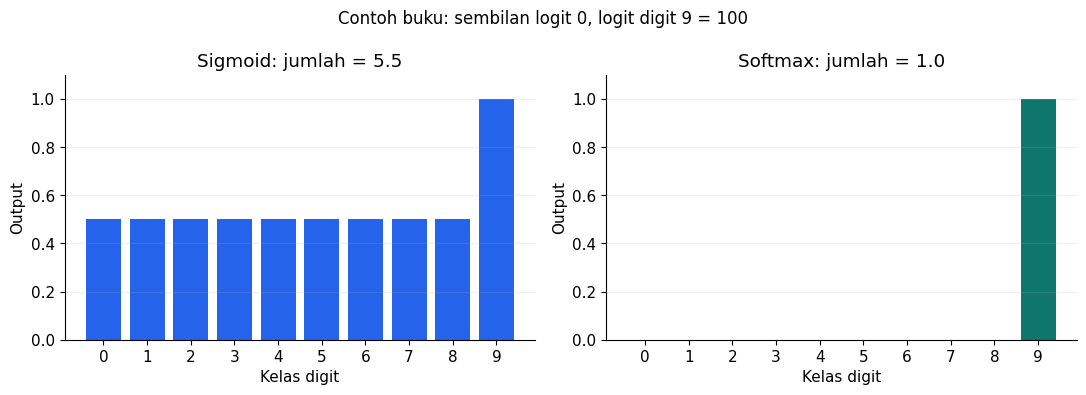

In [ ]:
# Grafik 2: distribusi berbeda pada logit dan target yang sama.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
digits = np.arange(10)
axes[0].bar(digits, example_sigmoid[0], color='#2563eb')
axes[0].set_title(f'Sigmoid: jumlah = {example_sigmoid.sum():.1f}')
axes[1].bar(digits, example_softmax[0], color='#0f766e')
axes[1].set_title(f'Softmax: jumlah = {example_softmax.sum():.1f}')
for ax in axes:
    ax.set(xlabel='Kelas digit', ylabel='Output', xticks=digits, ylim=(0, 1.1))
    ax.grid(axis='y', alpha=0.2)
fig.suptitle('Contoh buku: sembilan logit 0, logit digit 9 = 100', fontsize=12)
fig.tight_layout()
plt.show()

## 8. Softmax per baris, stabilitas, dan temperature

Untuk logit kelas $z_k$ pada satu sampel:

$$p_k=\frac{e^{z_k}}{\sum_j e^{z_j}}.$$

Pada matriks $B\times C$, normalisasi dilakukan pada **axis kelas**, yaitu `axis=1`, bukan atas semua sampel sekaligus. `keepdims=True` mempertahankan bentuk $B\times1$ untuk broadcasting. Output satu kelas bergantung pada semua logit dalam baris yang sama.

Softmax invariant terhadap penambahan konstanta pada seluruh logit satu sampel:

$$\operatorname{softmax}(z+c\mathbf1)=\operatorname{softmax}(z).$$

Karena itu kita dapat mengurangi setiap baris dengan nilai maksimumnya sebelum menghitung eksponensial. Cara ini menghindari overflow untuk logit besar. `argmax(softmax(z))=argmax(z)` karena eksponensial monoton naik dan denominator sama untuk semua kelas. Identitas inilah yang membenarkan evaluasi kelas menggunakan logit pada listing buku; untuk menghitung probabilitas atau cross-entropy tetap diperlukan softmax/log-softmax.

Temperature $\tau>0$ memberi $p=\operatorname{softmax}(z/\tau)$. Nilai $\tau$ kecil membuat distribusi lebih tajam, sedangkan nilai besar membuatnya lebih merata. Saran buku untuk mengganti basis eksponensial dengan $b>1$ setara dengan $\tau=1/\log b$, sebab $b^z=e^{z\log b}$. Temperatur tidak mengubah kelas argmax dan tidak otomatis memperbaiki calibration.

**Rujukan:** Trask (2019), hlm. 169; [dokumentasi SciPy softmax](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.softmax.html) untuk normalisasi dan shifting. Fungsi berikut memakai NumPy saja.

In [ ]:
# Pendalaman stabilitas; fungsi sumber softmax tetap dipakai untuk training reproduksi.
def softmax_stable(logits):
    logits = np.asarray(logits, dtype=np.float64)
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    exp_shifted = np.exp(shifted)
    return exp_shifted / exp_shifted.sum(axis=1, keepdims=True)

def log_softmax_stable(logits):
    logits = np.asarray(logits, dtype=np.float64)
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    return shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))

ordinary_logits = np.array([[1., 2., -1.], [0.5, -0.5, 0.]])
ordinary_probs = softmax_stable(ordinary_logits)
assert np.allclose(softmax(ordinary_logits), ordinary_probs)
assert np.allclose(softmax_stable(ordinary_logits + 1000), ordinary_probs)
assert np.allclose(ordinary_probs.sum(axis=1), 1)
assert np.array_equal(ordinary_logits.argmax(axis=1), ordinary_probs.argmax(axis=1))

extreme_logits = np.array([[1000., 1001., 999.], [-1000., -1001., -999.]])
with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
    naive_extreme = softmax(extreme_logits)
stable_extreme = softmax_stable(extreme_logits)
print('Softmax naif pada logit ekstrem finite?', np.isfinite(naive_extreme).all())
print('Softmax stabil pada logit ekstrem:\n', stable_extreme)
assert np.isfinite(stable_extreme).all()
assert np.allclose(stable_extreme.sum(axis=1), 1)

temperature_logits = np.array([[0., 1., 2.]])
for temperature in [0.5, 1.0, 2.0]:
    print(f'Temperature {temperature}:', softmax_stable(temperature_logits / temperature)[0])

Softmax naif pada logit ekstrem finite? False
Softmax stabil pada logit ekstrem:
 [[0.244728 0.665241 0.090031]
 [0.244728 0.090031 0.665241]]
Temperature 0.5: [0.015876 0.11731  0.866813]
Temperature 1.0: [0.090031 0.244728 0.665241]
Temperature 2.0: [0.186324 0.307196 0.50648 ]


## 9. Backpropagation: derivative lokal dan Jacobian

Untuk aktivasi elementwise $H=f(Z)$ dan upstream gradient $G=\partial L/\partial H$:

$$\frac{\partial L}{\partial Z}=G\odot f'(Z).$$

Jika hidden activation adalah tanh dan output delta terhadap logit adalah $D_2$, tanpa dropout:

$$D_1=(D_2W_{12}^{\mathsf T})\odot(1-H^2),\qquad
\nabla_{W_{01}}L=X^{\mathsf T}D_1,\qquad
\nabla_{W_{12}}L=H^{\mathsf T}D_2.$$

Softmax berbeda dari fungsi elementwise. Jacobian untuk satu sampel adalah:

$$J_{ij}=\frac{\partial p_i}{\partial z_j}=p_i(\delta_{ij}-p_j),\qquad
J=\operatorname{diag}(p)-pp^{\mathsf T}.$$

Turunan off-diagonal $-p_ip_j$ menjelaskan kompetisi antarkelas. Jika upstream gradient berupa vektor kolom $g_p$, maka $g_z=J^{\mathsf T}g_p$. Menggunakan hanya $p(1-p)$ akan menghilangkan pengaruh antaroutput.

**Catatan tabel hlm. 173:** baris ReLU menulis `deriv = output * mask`, padahal turunan yang benar adalah mask saja, yaitu `(z > 0)` atau `(ReLU(z) > 0)` dengan pilihan nol di titik nol. Baris forward softmax membuat `temp`, tetapi tidak mengisi `output = temp` sebelum pembagian. Fungsi lengkap di hlm. 174 memakai rumus forward yang benar. Baris backward softmax yang melibatkan `true` adalah delta gabungan dengan loss tertentu, bukan Jacobian softmax saja.

**Rujukan:** Trask (2019), hlm. 170-173. Jacobian dan pengujian berikut merupakan pendalaman.

In [ ]:
# Pendalaman: finite difference aktivasi dan semua elemen Jacobian softmax.
epsilon = 1e-6
derivative_points = np.array([-2., -0.3, 0., 0.4, 2.])
numerical_sigmoid = (sigmoid_stable(derivative_points + epsilon) -
                     sigmoid_stable(derivative_points - epsilon)) / (2*epsilon)
numerical_tanh = (tanh(derivative_points + epsilon) -
                  tanh(derivative_points - epsilon)) / (2*epsilon)
assert np.allclose(numerical_sigmoid, sigmoid2deriv(sigmoid_stable(derivative_points)), atol=1e-9)
assert np.allclose(numerical_tanh, tanh2deriv(tanh(derivative_points)), atol=1e-9)
relu_points = np.array([-2., -0.3, 0.4, 2.])  # Hindari titik nondifferentiable 0.
numerical_relu = (relu(relu_points + epsilon) - relu(relu_points - epsilon)) / (2*epsilon)
assert np.allclose(numerical_relu, relu_points > 0, atol=1e-9)

jacobian_logits = np.array([[0.2, -0.7, 1.3]])
jacobian_p = softmax_stable(jacobian_logits)[0]
jacobian_analytic = np.diag(jacobian_p) - np.outer(jacobian_p, jacobian_p)
jacobian_numeric = np.empty((3, 3))
for j in range(3):
    offset = np.zeros_like(jacobian_logits)
    offset[0, j] = epsilon
    jacobian_numeric[:, j] = (softmax_stable(jacobian_logits+offset)[0] -
                              softmax_stable(jacobian_logits-offset)[0]) / (2*epsilon)
assert np.allclose(jacobian_analytic, jacobian_numeric, atol=1e-9)
assert np.allclose(jacobian_analytic.sum(axis=0), 0)
activation_gradient_error = float(np.max(np.abs(jacobian_analytic - jacobian_numeric)))
print('Jacobian softmax:\n', jacobian_analytic)
print('Maksimum selisih Jacobian vs. finite difference:', format(activation_gradient_error, '.3e'))
print('Turunan sigmoid, tanh, ReLU (di luar nol), dan Jacobian softmax: sesuai.')

Jacobian softmax:
 [[ 0.175318 -0.020898 -0.154419]
 [-0.020898  0.083681 -0.062782]
 [-0.154419 -0.062782  0.217202]]
Maksimum selisih Jacobian vs. finite difference: 4.111e-11
Turunan sigmoid, tanh, ReLU (di luar nol), dan Jacobian softmax: sesuai.


## 10. Pendalaman: mengapa softmax + cross-entropy memberi delta p-y?

Untuk target categorical one-hot $y$ dengan $\sum_k y_k=1$, negative log-likelihood satu sampel adalah:

$$\ell(z,y)=-\sum_k y_k\log p_k
=-\sum_k y_kz_k+\log\sum_j e^{z_j}.$$

Dengan menurunkan terhadap $z_i$:

$$\frac{\partial\ell}{\partial z_i}=-y_i+
\frac{e^{z_i}}{\sum_j e^{z_j}}=p_i-y_i.$$

Jika loss batch merupakan rata-rata $L=\frac1B\sum_{n=1}^B\ell_n$, maka:

$$D_2=\frac{P-Y}{B}.$$

Pembagian batch dilakukan **sekali**. Tidak ada pembagian tambahan oleh jumlah kelas untuk categorical cross-entropy yang dirata-ratakan atas sampel. Rumus ini juga berlaku untuk target distribusi yang tiap barisnya berjumlah satu. Dengan squared error pada output softmax, gradiennya berbeda dan harus melewati Jacobian.

Pada konvensi gradien descent, update adalah $W\leftarrow W-\alpha\nabla_WL$. Buku menggunakan arah delta positif $Y-P$ dan update `+=`, yang setara jika faktor normalisasinya sama. Rumus source pada hlm. 175 membagi oleh `batch_size * layer_2.shape[0]`. Karena keduanya 100, delta sumber adalah $(Y-P)/B^2$, yaitu $1/B$ dari arah untuk mean cross-entropy. Ini mengubah skala update; bukan turunan softmax yang berbeda.

Loss dapat dihitung stabil dari logit menggunakan log-softmax. Jangan memakai `-log(softmax)` naif pada probabilitas yang sudah underflow menjadi nol. Menambahkan clipping akan mengubah nilai fungsi pada batas, sedangkan log-softmax berbasis shift menjaga formula aslinya.

**Rujukan:** Trask (2019), hlm. 173-175, menyebut cross-entropy tanpa pembahasan rinci. Derivasi di atas dan contoh berikut adalah pendalaman; [catatan praktikum Stanford CS231n](https://cs231n.github.io/neural-networks-case-study/) digunakan sebagai pemeriksaan pendamping.

In [ ]:
# Pendalaman: mean categorical cross-entropy dari logit dan gradien terhadap logit.
def mean_cross_entropy(logits, targets):
    return float(-np.mean(np.sum(targets * log_softmax_stable(logits), axis=1)))

ce_logits = np.array([[0.2, -0.4, 1.1], [1.0, 0.3, -0.7]])
ce_targets = np.eye(3)[[2, 0]]
ce_delta = (softmax_stable(ce_logits) - ce_targets) / len(ce_targets)
ce_numerical = np.zeros_like(ce_logits)
for index in np.ndindex(ce_logits.shape):
    plus, minus = ce_logits.copy(), ce_logits.copy()
    plus[index] += epsilon
    minus[index] -= epsilon
    ce_numerical[index] = (mean_cross_entropy(plus, ce_targets) -
                          mean_cross_entropy(minus, ce_targets)) / (2*epsilon)
ce_gradient_error = float(np.max(np.abs(ce_delta-ce_numerical)))
assert np.allclose(ce_delta, ce_numerical, atol=1e-9)
print('Mean cross-entropy contoh:', mean_cross_entropy(ce_logits, ce_targets))
print('Delta logit (p-y)/B:\n', ce_delta)
print('Maksimum selisih finite difference:', format(ce_gradient_error, '.3e'))
print('Loss untuk contoh logit ekstrem yang benar:',
      mean_cross_entropy(np.array([[1000., 0., -1000.]]), np.eye(3)[[0]]))

Mean cross-entropy contoh: 0.5033771577196904
Delta logit (p-y)/B:
 [[ 0.124738  0.068457 -0.193195]
 [-0.202251  0.147858  0.054394]]
Maksimum selisih finite difference: 3.928e-11
Loss untuk contoh logit ekstrem yang benar: -0.0


## 11. Data MNIST dan bentuk matriks

MNIST menyediakan gambar grayscale digit 0-9 berukuran 28 × 28. File resmi berisi 60.000 gambar training dan 10.000 gambar test. Buku mengambil **1.000 gambar training pertama**, meratakan setiap gambar menjadi 784 feature, lalu membagi pixel dengan 255 agar berada pada rentang 0-1. Label diubah menjadi one-hot vector dengan sepuluh elemen.

Validation tambahan memakai indeks training 1000-1999 yang tidak digunakan dalam update. Tidak ada perubahan pada training sumber akibat penambahan validation. Notebook tidak memilih learning rate atau jumlah epoch berdasarkan test maupun validation.

| Variabel | Bentuk | Arti |
| --- | --- | --- |
| `layer_0`, $X$ | $B\times784$ | Input batch |
| `weights_0_1`, $W_{01}$ | $784\times100$ | Bobot input-hidden |
| `Z_1`, `H`, mask | $B\times100$ | Preactivation, hidden tanh, dan dropout |
| `weights_1_2`, $W_{12}$ | $100\times10$ | Bobot hidden-output |
| Logit, `layer_2`, label | $B\times10$ | Skor, probabilitas, dan target |
| `layer_2_delta` | $B\times10$ | Arah update terhadap logit |
| `layer_1_delta` | $B\times100$ | Arah update terhadap preactivation hidden |

**Adaptasi loader:** buku memakai `keras.datasets.mnist.load_data()`. Sel berikut menyediakan antarmuka `load_data()` yang membaca file resmi yang sama langsung dengan NumPy dan memeriksa SHA-256 cache. Training tetap memakai NumPy.

**Rujukan:** Trask (2019), hlm. 174-175; [dokumentasi resmi dataset MNIST Keras](https://keras.io/api/datasets/mnist/).

In [ ]:
# Adaptasi loader: file MNIST resmi yang juga digunakan Keras.
MNIST_URL = 'https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz'
MNIST_SHA256 = '731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1'
DATA_CACHE = Path('data/mnist.npz')

class NumpyMNISTLoader:
    @staticmethod
    def load_data():
        DATA_CACHE.parent.mkdir(parents=True, exist_ok=True)
        if not DATA_CACHE.exists():
            urllib.request.urlretrieve(MNIST_URL, DATA_CACHE)
        actual_hash = hashlib.sha256(DATA_CACHE.read_bytes()).hexdigest()
        if actual_hash != MNIST_SHA256:
            raise ValueError('Hash cache MNIST berbeda. Hapus cache lalu unduh ulang.')
        with np.load(DATA_CACHE, allow_pickle=False) as dataset:
            return ((dataset['x_train'], dataset['y_train']),
                    (dataset['x_test'], dataset['y_test']))

mnist = NumpyMNISTLoader()
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print('Training tersedia:', x_train.shape, y_train.shape)
print('Test tersedia:', x_test.shape, y_test.shape)
print('Hash MNIST sesuai.')

Training tersedia: (60000, 28, 28) (60000,)
Test tersedia: (10000, 28, 28) (10000,)
Hash MNIST sesuai.


In [ ]:
# Reproduksi preprocessing halaman 174.
images, labels = (x_train[0:1000].reshape(1000, 28*28) / 255, y_train[0:1000])
one_hot_labels = np.zeros((len(labels), 10))
for i, l in enumerate(labels):
    one_hot_labels[i][l] = 1
labels = one_hot_labels

test_images = x_test.reshape(len(x_test), 28*28) / 255
test_labels = np.zeros((len(y_test), 10))
for i, l in enumerate(y_test):
    test_labels[i][l] = 1

# Validation tambahan; tidak digunakan untuk update atau tuning.
validation_images = x_train[1000:2000].reshape(1000, 28*28) / 255
validation_labels = np.eye(10)[y_train[1000:2000]]
assert np.intersect1d(np.arange(1000), np.arange(1000, 2000)).size == 0
assert images.shape == (1000, 784) and labels.shape == (1000, 10)
assert np.all(labels.sum(axis=1) == 1)
assert images.dtype == np.float64
print('Data yang dipakai: training', images.shape, '; validation', validation_images.shape,
      '; test', test_images.shape)
print('Rentang pixel training:', images.min(), images.max())
print('Jumlah label training per digit:', labels.sum(axis=0).astype(int))

Data yang dipakai: training (1000, 784) ; validation (1000, 784) ; test (10000, 784)
Rentang pixel training: 0.0 1.0
Jumlah label training per digit: [ 97 116  99  93 105  92  94 117  87 100]


## 12. Reproduksi cuplikan pemasangan ReLU pada hlm. 170-171

Cuplikan sumber memasang ReLU setelah dot product dan memberi output linear. Potongan ini adalah peninjauan jaringan sebelumnya, bukan program training tanh-softmax yang baru. Untuk menjalankannya mandiri, notebook menyiapkan bobot dan mengambil satu gambar MNIST; inisialisasi untuk demonstrasi merupakan tambahan.

Buku menggunakan delta positif target dikurangi prediksi dan update `+=`. Untuk output linear dengan loss $\frac12\mathrm{SSE}$, konvensi tanda itu benar. Akan tetapi, `relu2deriv(output) = output >= 0` pada hlm. 171 selalu bernilai benar pada hasil ReLU, termasuk activation nol yang berasal dari preactivation negatif. Ini berbeda dari narasi unit nonaktif yang seharusnya memberi gradien nol.

Sel berikut mereproduksi satu update sesuai cuplikan tersebut. Mask yang benar juga ditampilkan agar perbedaannya terlihat. Ini bukan penggantian diam-diam terhadap listing sumber.

**Rujukan:** Trask (2019), hlm. 170-171.

In [ ]:
# Reproduksi forward dan potongan update ReLU sumber pada satu sampel.
def relu2deriv(output):
    return output >= 0  # Perilaku sumber dipertahankan untuk demonstrasi.

demo_rng = np.random.RandomState(1)  # Tidak mengubah RNG program utama.
weights_0_1 = 0.2 * demo_rng.random_sample((784, 40)) - 0.1
weights_1_2 = 0.2 * demo_rng.random_sample((40, 10)) - 0.1
alpha, i = 0.005, 0
error, correct_cnt = 0.0, 0
layer_0 = images[i:i+1]
demo_preactivation = np.dot(layer_0, weights_0_1)
layer_1 = relu(np.dot(layer_0, weights_0_1))
layer_2 = np.dot(layer_1, weights_1_2)

error += np.sum((labels[i:i+1] - layer_2) ** 2)
correct_cnt += int(np.argmax(layer_2) == np.argmax(labels[i:i+1]))
layer_2_delta = (labels[i:i+1] - layer_2)
layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)
weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)

source_relu_mask = relu2deriv(layer_1)
correct_relu_mask = demo_preactivation > 0
assert source_relu_mask.all()
print('SSE sebelum satu update:', float(error))
print('Unit yang dianggap aktif oleh mask sumber:', int(source_relu_mask.sum()))
print('Unit dengan preactivation positif:', int(correct_relu_mask.sum()))
print('Mask berbeda pada', int(np.count_nonzero(source_relu_mask != correct_relu_mask)), 'unit.')

SSE sebelum satu update: 0.9317164986681463
Unit yang dianggap aktif oleh mask sumber: 40
Unit dengan preactivation positif: 19
Mask berbeda pada 21 unit.


## 13. Inisialisasi untuk tanh dan kaitannya dengan saturation

Buku mengubah bobot $W_{01}$ dari rentang sekitar $[-0{,}1,0{,}1)$ menjadi $[-0{,}01,0{,}01)$, sementara $W_{12}$ tetap sekitar $[-0{,}1,0{,}1)$. Preactivation tanh yang lebih dekat nol mempunyai turunan lebih besar sehingga sinyal backward lebih mudah mengalir pada awal training.

Jika input neuron adalah $z_j=\sum_i x_iw_{ij}$ dan bobot awal independen dengan mean nol serta variance $v$, maka dengan input tetap:

$$\operatorname{Var}(z_j\mid x)=v\sum_i x_i^2.$$

Uniform $[-a,a)$ memiliki variance $a^2/3$. Mengecilkan $a$ sepuluh kali mengecilkan standard deviation preactivation sepuluh kali untuk input yang sama. Namun initialization yang terlalu kecil juga dapat melemahkan representasi atau gradien; bobot nol semua menciptakan simetri antarunit. Bobot random pada sumber memecah simetri tersebut.

Eksperimen berikut memakai **angka random yang sama** dengan dua skala dan 256 gambar training. Persentase `|tanh(z)| > 0.95` hanyalah indikator saturation untuk demonstrasi, bukan batas yang dipakai trainer. Parameter ini tidak dipilih dari test.

**Rujukan:** Trask (2019), hlm. 174; analisis variance dan visualisasi adalah pendalaman.

In [ ]:
# Pendalaman: skala awal yang berbeda pada angka random dan input yang sama.
init_rng = np.random.RandomState(7)
unit_weights = 2 * init_rng.random_sample((784, 100)) - 1
init_stats = []
init_z = {}
for bound in [0.1, 0.01]:
    z_initial = images[:256] @ (bound * unit_weights)
    h_initial = tanh(z_initial)
    init_z[bound] = z_initial
    record = {'bound': bound, 'std_z': float(z_initial.std()),
              'mean_derivative': float(tanh2deriv(h_initial).mean()),
              'saturation_fraction': float(np.mean(np.abs(h_initial) > 0.95))}
    init_stats.append(record)
    print(f'Bobot ±{bound:g}: std(z)={record["std_z"]:.6f}; '
          f'rata-rata turunan={record["mean_derivative"]:.6f}; '
          f'|tanh(z)|>0.95={record["saturation_fraction"]:.2%}')
assert np.allclose(init_z[0.1], 10 * init_z[0.01])

Bobot ±0.1: std(z)=0.543820; rata-rata turunan=0.810781; |tanh(z)|>0.95=0.23%
Bobot ±0.01: std(z)=0.054382; rata-rata turunan=0.997062; |tanh(z)|>0.95=0.00%


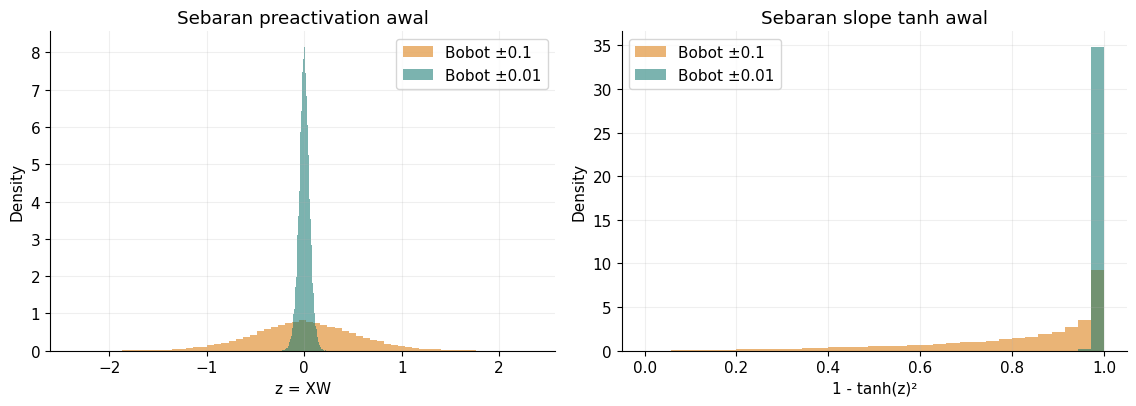

In [ ]:
# Grafik 3: initialization dan turunan tanh pada 256 gambar training.
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
colors = {0.1: '#d97706', 0.01: '#0f766e'}
for bound in [0.1, 0.01]:
    axes[0].hist(init_z[bound].ravel(), bins=65, density=True, alpha=0.55,
                 label=f'Bobot ±{bound:g}', color=colors[bound])
    axes[1].hist(tanh2deriv(tanh(init_z[bound])).ravel(), bins=np.linspace(0, 1, 36),
                 density=True, alpha=0.55, label=f'Bobot ±{bound:g}', color=colors[bound])
axes[0].set(title='Sebaran preactivation awal', xlabel='z = XW', ylabel='Density')
axes[1].set(title='Sebaran slope tanh awal', xlabel="1 - tanh(z)²", ylabel='Density')
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend()
fig.tight_layout()
plt.show()

## 14. Dropout, cache tanh, dan skala delta sumber

Untuk keep probability $q=0{,}5$, mask $M$ berisi 0 atau 1. Inverted dropout menghasilkan:

$$H=\tanh(Z_1),\qquad \widetilde H=H\odot M/q,\qquad Z_2=\widetilde HW_{12}.$$

Saat inference, gunakan $H$ utuh tanpa mask dan tanpa faktor 2. Saat backward yang konsisten:

$$D_2=(P-Y)/B,\qquad
D_1=(D_2W_{12}^{\mathsf T})\odot(M/q)\odot(1-H^2).$$

Ada tiga hal pada listing hlm. 175:

| Bagian sumber | Perilaku | Implikasi |
| --- | --- | --- |
| `layer_1 *= dropout_mask * 2` | `layer_1` berubah menjadi $\widetilde H$ | Cache tanh asli hilang jika tidak disimpan |
| `tanh2deriv(layer_1)` setelah perubahan itu | Menggunakan $1-\widetilde H^2$ | Bukan turunan tanh pada $Z_1$; bahkan dapat negatif |
| `layer_1_delta *= dropout_mask` | Backward hanya mengalikan $M$ | Faktor $1/q=2$ dari forward tidak ikut |
| Pembagi `batch_size * layer_2.shape[0]` | Membagi oleh $B^2$ | Skala delta $1/B$ dari mean cross-entropy |

Misalnya, $H=0{,}8$ dan $M=1$ memberi $\widetilde H=1{,}6$. Sumber memakai $1-1{,}6^2=-1{,}56$, sedangkan turunan komposisi tanh dan dropout adalah $2(1-0{,}8^2)=0{,}72$. Kesalahan cache bisa mengubah arah, sehingga tidak dapat diselesaikan hanya dengan mengganti learning rate.

Listing melakukan **satu update per batch**, di luar loop `for k` yang hanya menghitung accuracy. Indentasi ini diperiksa pada notebook resmi penulis. Ini menghasilkan 10 update per epoch dan 3.000 update selama 300 epoch.

Notebook mempertahankan ketiga perilaku gradien sumber untuk reproduksi, kemudian menyediakan implementasi tambahan sesuai rumus di atas. Nilai $\alpha=2$ tidak dapat dibandingkan langsung dengan trainer mean-gradient tanpa memperhitungkan pembagi batch.

**Rujukan:** Trask (2019), hlm. 174-175; [notebook pendamping resmi penulis](https://github.com/iamtrask/Grokking-Deep-Learning/blob/master/Chapter9%20-%20Intro%20to%20Activation%20Functions%20-%20Modeling%20Probabilities.ipynb).

In [ ]:
# Pendalaman: salah memakai cache yang telah di-dropout bisa membalik tanda slope.
raw_hidden_demo = np.array([[-0.8, -0.3, 0.0, 0.3, 0.8]])
fixed_mask_demo = np.ones_like(raw_hidden_demo)
dropped_hidden_demo = raw_hidden_demo * fixed_mask_demo * 2
source_local_factor = tanh2deriv(dropped_hidden_demo) * fixed_mask_demo
correct_local_factor = tanh2deriv(raw_hidden_demo) * fixed_mask_demo * 2
print('Tanh asli:', raw_hidden_demo)
print('Tanh setelah inverted dropout:', dropped_hidden_demo)
print('Faktor backward sumber:', source_local_factor)
print('Faktor backward konsisten:', correct_local_factor)
assert source_local_factor[0, -1] < 0
assert np.isclose(correct_local_factor[0, -1], 0.72)

Tanh asli: [[-0.8 -0.3  0.   0.3  0.8]]
Tanh setelah inverted dropout: [[-1.6 -0.6  0.   0.6  1.6]]
Faktor backward sumber: [[-1.56  0.64  1.    0.64 -1.56]]
Faktor backward konsisten: [[0.72 1.82 2.   1.82 0.72]]


## 15. Evaluasi inference dan loss tambahan

Saat mengevaluasi model, seluruh unit hidden digunakan tanpa dropout. Buku menghitung kelas dari logit tanpa softmax; argmax-nya sama dengan argmax probabilitas softmax. Evaluasi tambahan menghitung mean categorical cross-entropy serta accuracy dari **satu keadaan bobot tetap**.

Mean cross-entropy adalah rata-rata loss per gambar dengan log natural, bukan MSE dan bukan jumlah loss seluruh test. Loss tetap bermakna saat accuracy sudah tinggi: prediksi kelas yang benar bisa mempunyai probabilitas target rendah. Trainer reproduksi tidak memakai loss tambahan ini untuk update atau memilih checkpoint.

Accuracy training pada log buku adalah **online dengan dropout**. Sampel batch awal dan akhir melihat bobot berbeda, sehingga nilainya bukan accuracy seluruh training pada bobot terakhir. Notebook membedakan metrik itu dari accuracy inference training tanpa dropout.

Sel evaluasi vectorized berikut merupakan adaptasi untuk efisiensi. Input diproses dalam potongan tanpa pengacakan atau mask, sehingga evaluasi tidak mengonsumsi angka random yang dipakai training. Loop inference asli disertakan untuk verifikasi.

**Rujukan:** Trask (2019), hlm. 175; loss serta evaluasi beberapa split adalah pendalaman.

In [ ]:
# Evaluasi tambahan: seluruh split memakai bobot tetap dan dropout dimatikan.
def evaluate_tanh_network(X, Y, W01, W12, chunk_size=1000):
    total_loss, total_correct = 0.0, 0
    for start in range(0, len(X), chunk_size):
        Xb, Yb = X[start:start+chunk_size], Y[start:start+chunk_size]
        logits = tanh(Xb @ W01) @ W12
        log_probabilities = log_softmax_stable(logits)
        total_loss -= float(np.sum(Yb * log_probabilities))
        total_correct += int(np.sum(logits.argmax(axis=1) == Yb.argmax(axis=1)))
    return {'cross_entropy': total_loss / len(X),
            'accuracy': total_correct / len(X), 'correct': total_correct}

def collect_inference_metrics(W01, W12):
    return {
        'train': evaluate_tanh_network(images, labels, W01, W12),
        'validation': evaluate_tanh_network(validation_images, validation_labels, W01, W12),
        'test': evaluate_tanh_network(test_images, test_labels, W01, W12),
    }

def source_inference_loop(W01, W12):
    # Reproduksi loop evaluasi halaman 175, tanpa dropout/softmax.
    test_correct_cnt = 0
    for i in range(len(test_images)):
        layer_0 = test_images[i:i+1]
        layer_1 = tanh(np.dot(layer_0, W01))
        layer_2 = np.dot(layer_1, W12)
        test_correct_cnt += int(np.argmax(layer_2) == np.argmax(test_labels[i:i+1]))
    return test_correct_cnt

## 16. Reproduksi program utama MNIST: 300 epoch

Konfigurasi sumber: seed 1, hidden size 100, batch size 100, $\alpha=2$, 300 epoch, tanpa bias, tanpa shuffle, tanh pada hidden, softmax pada output, dan inverted dropout 50%. Bobot input-hidden dimulai pada rentang -0,01 sampai 0,01.

Forward dan update di sel berikut mengikuti listing, termasuk cache tanh setelah dropout, mask backward tanpa faktor 2, serta pembagi $B^2$. History, timer, pemeriksaan finite, hitungan update, dan telemetry faktor negatif adalah tambahan yang tidak mengubah bobot. Evaluasi test source dialihkan ke fungsi matriks pada checkpoint; tidak ada epoch atau update training yang dilewati.

`I:0` berarti epoch pertama sudah dijalankan. `I:290` berarti epoch ke-291; buku mencetak sampai indeks itu karena kondisi `%10`. Notebook juga melaporkan indeks 299, yaitu seluruh 300 epoch. Angka buku dipakai hanya sebagai pembanding di sel verifikasi, bukan sebagai output yang dikarang.

**Rujukan:** Trask (2019), hlm. 174-175.

In [ ]:
# Reproduksi training sumber. Perilaku gradien sumber dipertahankan.
np.random.seed(1)
alpha, iterations, hidden_size = (2, 300, 100)
pixels_per_image, num_labels = (784, 10)
batch_size = 100
weights_0_1 = 0.02*np.random.random((pixels_per_image, hidden_size))-0.01
weights_1_2 = 0.2*np.random.random((hidden_size, num_labels))-0.1
book_initial_W01 = weights_0_1.copy()
book_initial_W12 = weights_1_2.copy()

book_history, book_online_history = [], []
book_updates, book_negative_factor_count, book_retained_count = 0, 0, 0
book_training_seconds = 0.0

for j in range(iterations):
    epoch_started = time.perf_counter()
    correct_cnt = 0
    for i in range(int(len(images) / batch_size)):
        batch_start, batch_end = ((i*batch_size), ((i+1)*batch_size))
        layer_0 = images[batch_start:batch_end]
        layer_1 = tanh(np.dot(layer_0, weights_0_1))
        dropout_mask = np.random.randint(2, size=layer_1.shape)
        layer_1 *= dropout_mask * 2
        layer_2 = softmax(np.dot(layer_1, weights_1_2))

        for k in range(batch_size):
            correct_cnt += int(np.argmax(layer_2[k:k+1]) ==
                               np.argmax(labels[batch_start+k:batch_start+k+1]))

        layer_2_delta = (labels[batch_start:batch_end]-layer_2) / (batch_size*layer_2.shape[0])
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * tanh2deriv(layer_1)
        layer_1_delta *= dropout_mask
        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)

        # Telemetry tambahan, tidak mengubah perhitungan update di atas.
        book_updates += 1
        book_retained_count += int(dropout_mask.sum())
        book_negative_factor_count += int(np.count_nonzero((np.abs(layer_1) > 1) & (dropout_mask == 1)))
        assert np.isfinite(layer_2).all()
        assert np.allclose(layer_2.sum(axis=1), 1)

    book_training_seconds += time.perf_counter() - epoch_started
    online_accuracy = correct_cnt / float(len(images))
    book_online_history.append({'index': j, 'online_accuracy': online_accuracy})
    if j % 10 == 0 or j == iterations-1:
        metrics = collect_inference_metrics(weights_0_1, weights_1_2)
        book_history.append({'index': j, 'epoch': j+1,
                             'online_accuracy': online_accuracy, **metrics})
        print(f'I:{j:3d} Test-Acc:{metrics["test"]["accuracy"]:.4f} '
              f'Train-Acc-online:{online_accuracy:.3f} '
              f'Train-Acc-inference:{metrics["train"]["accuracy"]:.3f} '
              f'Val-Acc:{metrics["validation"]["accuracy"]:.3f}')

book_W01, book_W12 = weights_0_1.copy(), weights_1_2.copy()
book_final = collect_inference_metrics(book_W01, book_W12)
assert book_updates == iterations * (len(images)//batch_size) == 3000
assert len(book_online_history) == 300 and book_history[-1]['index'] == 299
assert np.isfinite(book_W01).all() and np.isfinite(book_W12).all()
print('Update sumber:', book_updates, '; epoch:', iterations)
print('Waktu loop training, di luar evaluasi checkpoint:', round(book_training_seconds, 2), 'detik')
print('Faktor 1-layer_1² negatif pada unit retained sepanjang training:',
      f'{book_negative_factor_count/book_retained_count:.2%}')

I:  0 Test-Acc:0.3940 Train-Acc-online:0.156 Train-Acc-inference:0.425 Val-Acc:0.397
I: 10 Test-Acc:0.6867 Train-Acc-online:0.723 Train-Acc-inference:0.734 Val-Acc:0.700
I: 20 Test-Acc:0.7025 Train-Acc-online:0.732 Train-Acc-inference:0.746 Val-Acc:0.716
I: 30 Test-Acc:0.7340 Train-Acc-online:0.763 Train-Acc-inference:0.778 Val-Acc:0.748
I: 40 Test-Acc:0.7663 Train-Acc-online:0.794 Train-Acc-inference:0.812 Val-Acc:0.773
I: 50 Test-Acc:0.7913 Train-Acc-online:0.819 Train-Acc-inference:0.842 Val-Acc:0.799
I: 60 Test-Acc:0.8102 Train-Acc-online:0.849 Train-Acc-inference:0.861 Val-Acc:0.821
I: 70 Test-Acc:0.8228 Train-Acc-online:0.864 Train-Acc-inference:0.876 Val-Acc:0.826
I: 80 Test-Acc:0.8310 Train-Acc-online:0.867 Train-Acc-inference:0.885 Val-Acc:0.845
I: 90 Test-Acc:0.8364 Train-Acc-online:0.885 Train-Acc-inference:0.892 Val-Acc:0.852
I:100 Test-Acc:0.8407 Train-Acc-online:0.883 Train-Acc-inference:0.899 Val-Acc:0.855
I:110 Test-Acc:0.8450 Train-Acc-online:0.891 Train-Acc-inference:

## 17. Memeriksa checkpoint sumber dan loop evaluasi

Angka pembanding berikut berasal dari tabel hlm. 175. Pencetakan buku membulatkan sebagian training accuracy, sedangkan notebook penulis menyediakan angka lengkap. Karena itu verifikasi exact accuracy online memakai checkpoint yang tidak terpotong; test accuracy memakai nilai empat desimal pada sumber.

Hasil akhir juga diperiksa menggunakan loop satu sampel dari sumber. Jika loop dan evaluator matriks menghasilkan jumlah kelas benar yang sama, adaptasi evaluasi telah mempertahankan keputusan kelas pada hasil tersebut. Pemeriksaan ini tidak mengasumsikan semua bit floating point dari perkalian matriks identik.

Sumber menunjukkan test accuracy sekitar 87%. Nilai ini adalah hasil satu eksperimen dengan 1.000 sampel training; jangan menganggapnya ukuran kinerja semua arsitektur tanh-softmax.

In [ ]:
# Verifikasi terhadap checkpoint buku dan output notebook resmi penulis.
book_expected_test = {0: 0.3940, 10: 0.6867, 50: 0.7913, 100: 0.8407,
                      150: 0.8555, 200: 0.8642, 270: 0.8703, 290: 0.8701}
book_expected_online = {0: 0.156, 10: 0.723, 50: 0.819, 150: 0.914, 290: 0.940}
book_by_index = {row['index']: row for row in book_history}
for index, expected in book_expected_test.items():
    actual = book_by_index[index]['test']['accuracy']
    assert np.isclose(actual, expected, atol=1e-12), (index, actual, expected)
for index, expected in book_expected_online.items():
    actual = book_by_index[index]['online_accuracy']
    assert np.isclose(actual, expected, atol=1e-12), (index, actual, expected)

source_loop_correct = source_inference_loop(book_W01, book_W12)
assert source_loop_correct == book_final['test']['correct']
print('Delapan checkpoint test dan lima checkpoint online cocok dengan sumber.')
print('Loop test satu per satu:', source_loop_correct, '/', len(test_images))
print('Evaluasi matriks:', book_final['test']['correct'], '/', len(test_images))
print('Checkpoint indeks 290:', book_by_index[290]['test']['accuracy'])
print('Seluruh 300 epoch, indeks 299:', book_final['test']['accuracy'])

Delapan checkpoint test dan lima checkpoint online cocok dengan sumber.
Loop test satu per satu: 8706 / 10000
Evaluasi matriks: 8706 / 10000
Checkpoint indeks 290: 0.8701
Seluruh 300 epoch, indeks 299: 0.8706


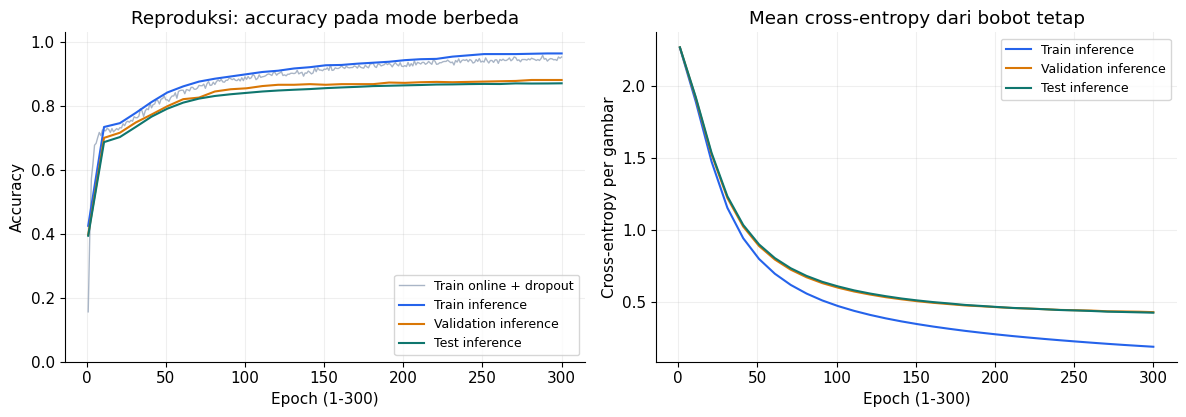

In [ ]:
# Grafik 4: metrik sumber online vs. inference dan loss tambahan.
book_epochs = np.array([row['epoch'] for row in book_history])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].plot(np.arange(1, 301), [row['online_accuracy'] for row in book_online_history],
             color='#94a3b8', linewidth=1, alpha=0.8, label='Train online + dropout')
split_colors = {'train': '#2563eb', 'validation': '#d97706', 'test': '#0f766e'}
for split, color in split_colors.items():
    axes[0].plot(book_epochs, [row[split]['accuracy'] for row in book_history],
                 color=color, label=f'{split.title()} inference')
    axes[1].plot(book_epochs, [row[split]['cross_entropy'] for row in book_history],
                 color=color, label=f'{split.title()} inference')
axes[0].set(title='Reproduksi: accuracy pada mode berbeda', xlabel='Epoch (1-300)',
            ylabel='Accuracy', ylim=(0, 1.03))
axes[1].set(title='Mean cross-entropy dari bobot tetap', xlabel='Epoch (1-300)',
            ylabel='Cross-entropy per gambar')
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 18. Pendalaman: memeriksa gradien tanh + dropout + softmax

Finite difference memeriksa apakah arah analitik cocok dengan turunan loss numerik:

$$g_i^{\mathrm{numerik}}\approx
\frac{L(\theta+\varepsilon e_i)-L(\theta-\varepsilon e_i)}{2\varepsilon}.$$

Mask dropout **harus tetap sama** pada evaluasi plus dan minus. Jika setiap evaluasi memakai mask baru, perbedaan loss mencampur perubahan bobot dan perubahan random sehingga tidak menguji turunan dari fungsi yang sama.

Contoh kecil berikut memakai dua sampel, tiga input, empat hidden unit, tiga kelas, dan semua **24 bobot** diperiksa. Bobot output dan hidden gradient dihitung dari keadaan bobot yang sama sebelum update. Perbandingan dengan arah descent listing sumber dinormalisasi ulang dengan mengalikan $B$ agar pembagi $B^2$ tidak menutupi masalah cache/scaling hidden.

In [ ]:
# Implementasi tambahan: gradien konsisten untuk mask yang diberikan.
def consistent_loss_and_gradients(X, Y, W01, W12, mask, keep_probability=0.5):
    if not 0 < keep_probability <= 1:
        raise ValueError('keep_probability harus di (0, 1].')
    hidden = tanh(X @ W01)  # Simpan cache sebelum dropout.
    multiplier = mask / keep_probability
    hidden_dropout = hidden * multiplier
    logits = hidden_dropout @ W12
    probabilities = softmax_stable(logits)
    D2 = (probabilities - Y) / len(X)
    D1 = (D2 @ W12.T) * multiplier * tanh2deriv(hidden)
    G01, G12 = X.T @ D1, hidden_dropout.T @ D2
    return mean_cross_entropy(logits, Y), G01, G12, probabilities

toy_rng = np.random.RandomState(13)
toy_X = np.array([[1.0, -0.7, 0.8], [-0.6, 1.0, 0.5]])
toy_Y = np.eye(3)[[0, 2]]
toy_W01 = toy_rng.uniform(-0.9, 0.9, (3, 4))
toy_W12 = toy_rng.uniform(-0.5, 0.5, (4, 3))
toy_mask = np.array([[1, 0, 1, 1], [0, 1, 1, 1]], dtype=float)
toy_loss, toy_G01, toy_G12, toy_p = consistent_loss_and_gradients(
    toy_X, toy_Y, toy_W01, toy_W12, toy_mask)

all_numeric_gradients = []
for which, weights, analytic in [(0, toy_W01, toy_G01), (1, toy_W12, toy_G12)]:
    numerical = np.zeros_like(weights)
    for index in np.ndindex(weights.shape):
        plus, minus = weights.copy(), weights.copy()
        plus[index] += epsilon
        minus[index] -= epsilon
        if which == 0:
            loss_plus = consistent_loss_and_gradients(toy_X, toy_Y, plus, toy_W12, toy_mask)[0]
            loss_minus = consistent_loss_and_gradients(toy_X, toy_Y, minus, toy_W12, toy_mask)[0]
        else:
            loss_plus = consistent_loss_and_gradients(toy_X, toy_Y, toy_W01, plus, toy_mask)[0]
            loss_minus = consistent_loss_and_gradients(toy_X, toy_Y, toy_W01, minus, toy_mask)[0]
        numerical[index] = (loss_plus-loss_minus)/(2*epsilon)
    assert np.allclose(numerical, analytic, atol=1e-8, rtol=1e-6)
    all_numeric_gradients.append(numerical)

network_gradient_max_error = float(max(np.max(np.abs(all_numeric_gradients[0]-toy_G01)),
                                     np.max(np.abs(all_numeric_gradients[1]-toy_G12))))
toy_hidden = tanh(toy_X @ toy_W01)
toy_hidden_dropout = toy_hidden * toy_mask * 2
toy_source_D2 = (toy_p-toy_Y) / (len(toy_X)**2)  # Bentuk descent, berlawanan tanda source +=.
toy_source_D1 = (toy_source_D2 @ toy_W12.T) * tanh2deriv(toy_hidden_dropout) * toy_mask
toy_source_G12_rescaled = len(toy_X) * (toy_hidden_dropout.T @ toy_source_D2)
toy_source_G01_rescaled = len(toy_X) * (toy_X.T @ toy_source_D1)
assert np.allclose(toy_source_G12_rescaled, toy_G12)
listing_hidden_gradient_gap = float(np.max(np.abs(toy_source_G01_rescaled-toy_G01)))
assert listing_hidden_gradient_gap > 1e-4
print('Loss contoh kecil:', toy_loss)
print('Semua', toy_W01.size+toy_W12.size, 'bobot lolos pemeriksaan gradien.')
print('Maksimum selisih gradien:', format(network_gradient_max_error, '.3e'))
print('W12 source setelah koreksi skala B: sesuai.')
print('Maksimum selisih W01 source setelah koreksi skala B:', listing_hidden_gradient_gap)

Loss contoh kecil: 1.5602136468700067
Semua 24 bobot lolos pemeriksaan gradien.
Maksimum selisih gradien: 1.339e-10
W12 source setelah koreksi skala B: sesuai.
Maksimum selisih W01 source setelah koreksi skala B: 0.7096578307268113


In [ ]:
# Pendalaman mini-batch: gradien batch adalah rata-rata gradien sampel.
sample_gradients = [consistent_loss_and_gradients(
    toy_X[n:n+1], toy_Y[n:n+1], toy_W01, toy_W12, toy_mask[n:n+1])
    for n in range(len(toy_X))]
assert np.allclose(np.mean([item[1] for item in sample_gradients], axis=0), toy_G01)
assert np.allclose(np.mean([item[2] for item in sample_gradients], axis=0), toy_G12)
assert np.isclose(np.mean([item[0] for item in sample_gradients]), toy_loss)
print('Mean loss dan kedua gradien batch sesuai rata-rata gradien sampel pada bobot/mask yang sama.')

Mean loss dan kedua gradien batch sesuai rata-rata gradien sampel pada bobot/mask yang sama.


## 19. Pendalaman: trainer dengan aturan rantai yang konsisten

Implementasi tambahan memakai arsitektur, data, seed, initial weights, urutan batch, dropout 50%, dan 300 epoch yang sama. Perubahan: simpan tanh asli sebelum dropout, terapkan multiplier dropout pada backward, gunakan stable softmax, bagi delta hanya sekali dengan ukuran batch aktual, lalu lakukan satu update per batch.

Learning rate ditetapkan **0,02** sebelum melihat hasil test. Alasannya bersifat aljabar: sumber memakai $\alpha=2$ dan gradien output dibagi $B^2$. Trainer tambahan memakai gradien mean yang dibagi $B$, sehingga $\alpha_{\mathrm{tambahan}}=2/B=0{,}02$ menyamakan skala update $W_{12}$ untuk forward yang sama. Kedua model selanjutnya mengikuti lintasan berbeda karena backward $W_{01}$ diperbaiki.

Koreksi gradien dapat mengubah hasil training tanpa menjamin accuracy lebih tinggi. Perbandingan dua run ini memeriksa akibat perubahan implementasi dalam konfigurasi tersebut; bukan studi dengan banyak seed atau klaim keunggulan universal. Tidak ada pencarian learning rate pada test. Validation hanya dilaporkan dan tidak dipakai memilih checkpoint pada bab ini.

In [ ]:
# Pendalaman: 300 epoch dengan mean CE, cache benar, dan satu update per batch.
corrected_rng = np.random.RandomState(1)
corrected_W01 = 0.02*corrected_rng.random_sample((784, 100))-0.01
corrected_W12 = 0.2*corrected_rng.random_sample((100, 10))-0.1
assert np.array_equal(corrected_W01, book_initial_W01)
assert np.array_equal(corrected_W12, book_initial_W12)

corrected_alpha, corrected_iterations, corrected_batch_size = 0.02, 300, 100
keep_probability = 0.5
corrected_history, corrected_online_history = [], []
corrected_updates, corrected_training_seconds = 0, 0.0
for j in range(corrected_iterations):
    epoch_started = time.perf_counter()
    online_correct, online_loss_sum = 0, 0.0
    for start in range(0, len(images), corrected_batch_size):
        Xb, Yb = images[start:start+corrected_batch_size], labels[start:start+corrected_batch_size]
        mask = corrected_rng.randint(2, size=(len(Xb), 100))
        loss, G01, G12, probabilities = consistent_loss_and_gradients(
            Xb, Yb, corrected_W01, corrected_W12, mask, keep_probability)
        online_correct += int(np.sum(probabilities.argmax(axis=1) == Yb.argmax(axis=1)))
        online_loss_sum += loss * len(Xb)
        # Kedua gradien sudah dihitung dari bobot sebelum perubahan.
        corrected_W12 -= corrected_alpha * G12
        corrected_W01 -= corrected_alpha * G01
        corrected_updates += 1
        assert np.isfinite(loss)
    corrected_training_seconds += time.perf_counter() - epoch_started
    corrected_online_history.append({'index': j, 'online_accuracy': online_correct/len(images),
                                     'online_cross_entropy': online_loss_sum/len(images)})
    if j % 10 == 0 or j == corrected_iterations-1:
        metrics = collect_inference_metrics(corrected_W01, corrected_W12)
        corrected_history.append({'index': j, 'epoch': j+1,
                                  'online_accuracy': online_correct/len(images), **metrics})
        print(f'I:{j:3d} Test-Acc:{metrics["test"]["accuracy"]:.4f} '
              f'Train-Acc-online:{online_correct/len(images):.3f} '
              f'Train-Acc-inference:{metrics["train"]["accuracy"]:.3f} '
              f'Val-Acc:{metrics["validation"]["accuracy"]:.3f}')

corrected_final = collect_inference_metrics(corrected_W01, corrected_W12)
assert corrected_updates == 3000
assert len(corrected_online_history) == 300
assert np.isfinite(corrected_W01).all() and np.isfinite(corrected_W12).all()
print('Update tambahan:', corrected_updates, '; epoch:', corrected_iterations)
print('Waktu loop training, di luar evaluasi checkpoint:', round(corrected_training_seconds, 2), 'detik')

I:  0 Test-Acc:0.5647 Train-Acc-online:0.268 Train-Acc-inference:0.634 Val-Acc:0.583
I: 10 Test-Acc:0.7037 Train-Acc-online:0.736 Train-Acc-inference:0.744 Val-Acc:0.717
I: 20 Test-Acc:0.7546 Train-Acc-online:0.772 Train-Acc-inference:0.797 Val-Acc:0.763
I: 30 Test-Acc:0.7945 Train-Acc-online:0.819 Train-Acc-inference:0.845 Val-Acc:0.802
I: 40 Test-Acc:0.8151 Train-Acc-online:0.850 Train-Acc-inference:0.864 Val-Acc:0.826
I: 50 Test-Acc:0.8291 Train-Acc-online:0.868 Train-Acc-inference:0.883 Val-Acc:0.837
I: 60 Test-Acc:0.8365 Train-Acc-online:0.882 Train-Acc-inference:0.896 Val-Acc:0.846
I: 70 Test-Acc:0.8440 Train-Acc-online:0.893 Train-Acc-inference:0.900 Val-Acc:0.855
I: 80 Test-Acc:0.8488 Train-Acc-online:0.899 Train-Acc-inference:0.908 Val-Acc:0.860
I: 90 Test-Acc:0.8522 Train-Acc-online:0.904 Train-Acc-inference:0.918 Val-Acc:0.867
I:100 Test-Acc:0.8554 Train-Acc-online:0.906 Train-Acc-inference:0.923 Val-Acc:0.870
I:110 Test-Acc:0.8590 Train-Acc-online:0.917 Train-Acc-inference:

In [ ]:
# Tabel hasil dihitung dari model yang benar-benar dieksekusi.
comparison_rows = []
for name, metrics in [('Listing buku', book_final), ('Gradien konsisten (tambahan)', corrected_final)]:
    row = {'model': name,
           'train_accuracy': metrics['train']['accuracy'],
           'validation_accuracy': metrics['validation']['accuracy'],
           'test_accuracy': metrics['test']['accuracy'],
           'test_cross_entropy': metrics['test']['cross_entropy']}
    comparison_rows.append(row)
comparison_table = '| Model, setelah 300 epoch | Train inference | Validation | Test | Test mean CE |\n'
comparison_table += '| --- | --- | --- | --- | --- |\n'
for row in comparison_rows:
    comparison_table += (f'| {row["model"]} | {row["train_accuracy"]:.2%} | '
                         f'{row["validation_accuracy"]:.2%} | {row["test_accuracy"]:.2%} | '
                         f'{row["test_cross_entropy"]:.6f} |\n')
print(comparison_table)
print('Training online terakhir pada source:', book_online_history[-1]['online_accuracy'])
print('Training inference terakhir pada source:', book_final['train']['accuracy'])

| Model, setelah 300 epoch | Train inference | Validation | Test | Test mean CE |
| --- | --- | --- | --- | --- |
| Listing buku | 96.40% | 88.10% | 87.06% | 0.423425 |
| Gradien konsisten (tambahan) | 97.60% | 87.70% | 86.66% | 0.436692 |

Training online terakhir pada source: 0.953
Training inference terakhir pada source: 0.964


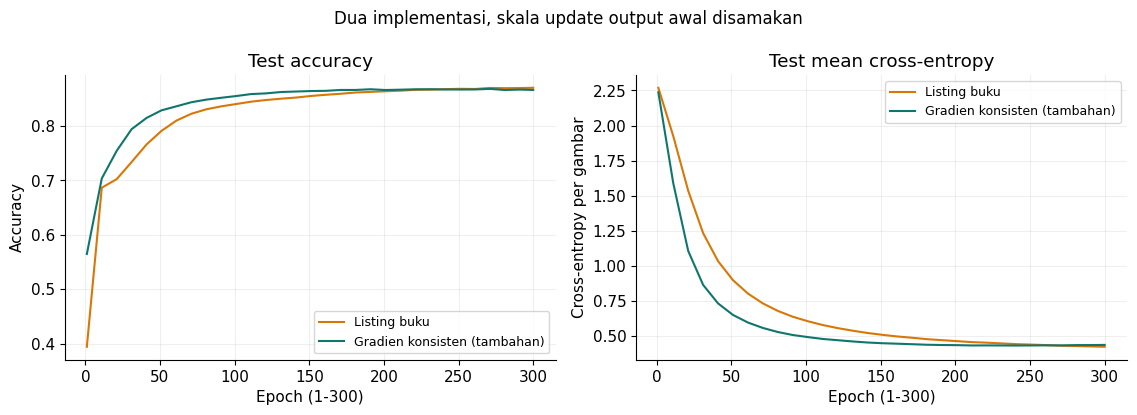

In [ ]:
# Grafik 5: hasil dua program; kurva test untuk laporan, bukan tuning.
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for name, history, color in [('Listing buku', book_history, '#d97706'),
                              ('Gradien konsisten (tambahan)', corrected_history, '#0f766e')]:
    epochs = [row['epoch'] for row in history]
    axes[0].plot(epochs, [row['test']['accuracy'] for row in history], color=color, label=name)
    axes[1].plot(epochs, [row['test']['cross_entropy'] for row in history], color=color, label=name)
axes[0].set(title='Test accuracy', xlabel='Epoch (1-300)', ylabel='Accuracy')
axes[1].set(title='Test mean cross-entropy', xlabel='Epoch (1-300)', ylabel='Cross-entropy per gambar')
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
fig.suptitle('Dua implementasi, skala update output awal disamakan', fontsize=12)
fig.tight_layout()
plt.show()

## 20. Hasil, interpretasi, dan batas perbandingan

| Model, setelah 300 epoch | Train inference | Validation | Test | Test mean CE |
| --- | --- | --- | --- | --- |
| Listing buku | 96.40% | 88.10% | 87.06% | 0.423425 |
| Gradien konsisten (tambahan) | 97.60% | 87.70% | 86.66% | 0.436692 |

Tabel di atas diisi otomatis dari **bobot akhir setelah 300 epoch**, bukan disalin dari buku. Accuracy inference training memakai seluruh 1.000 gambar dengan satu keadaan bobot dan dropout dimatikan. Angka training online terakhir listing buku adalah **95.30%**, sedangkan training inference terakhirnya **96.40%**; keduanya mengukur kondisi yang berbeda.

Checkpoint sumber `I:290` menghasilkan test accuracy **87.01%**. Hasil akhir indeks 299 adalah **87.06%**. Indeks dan aturan logging menjelaskan mengapa angka akhir notebook tidak harus sama dengan baris terakhir yang dicetak buku.

Mean cross-entropy menilai probabilitas target, sementara accuracy hanya menilai argmax. Dua model dengan accuracy mirip dapat mempunyai cross-entropy berbeda. Kurva training dan validation membantu membaca gap generalisasi, tetapi bab ini tidak melakukan pemilihan model berdasarkan test atau validation.

Perbaikan cache/scaling mengubah update hidden. Pemeriksaan finite difference memberi bukti bahwa implementasi tambahan sesuai dengan **loss mean categorical cross-entropy untuk mask tetap**. Itu tidak membuktikan konvergensi global, tidak menjamin perbaikan test accuracy, dan tidak menguji calibration.

Perbandingan dengan Chapter 8 juga tidak dapat mengisolasi efek tanh atau softmax saja: loss, rentang awal bobot, skala delta, dan pola update ikut berubah. Untuk studi sebab-akibat diperlukan eksperimen terkontrol dengan konfigurasi yang disamakan dan beberapa seed. Notebook ini menyelesaikan reproduksi satu konfigurasi buku serta satu pendalaman matematis yang transparan.

## 21. Membaca kesalahan per kelas

Confusion matrix berikut menempatkan **label sebenarnya pada baris** dan **prediksi pada kolom**. Elemen diagonal adalah klasifikasi benar; elemen di luar diagonal menunjukkan pasangan digit yang tertukar. Jumlah semua elemen harus 10.000 dan jumlah diagonal harus sama dengan hitungan benar evaluator.

Contoh gambar berikut mengambil enam prediksi benar pertama dan enam prediksi salah pertama dari test untuk listing buku. Pemilihan ini adalah ilustrasi kesalahan, bukan sampel acak untuk mengestimasi kinerja. Confidence yang terlihat hanya keluaran softmax model dan tidak boleh dibaca sebagai jaminan benar.

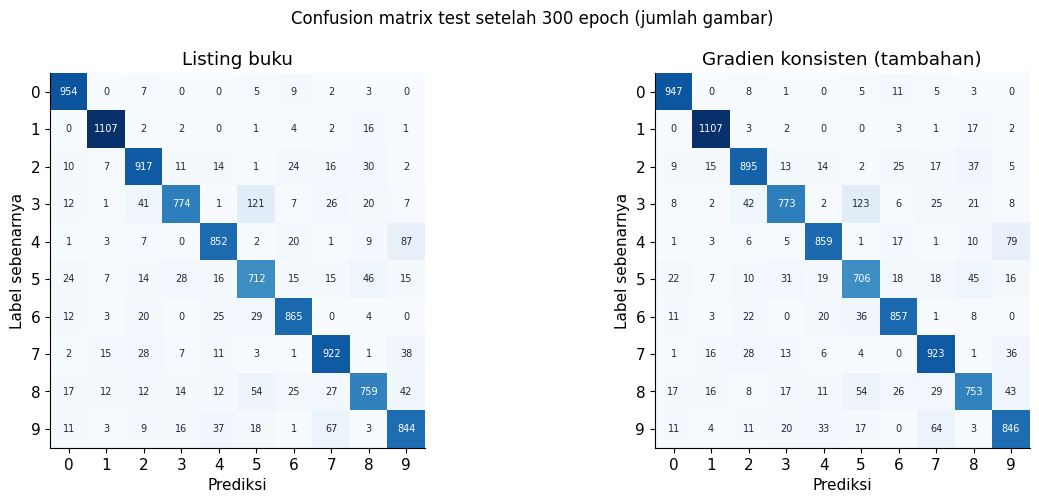

Diagonal source: 8706 ; total: 10000


In [ ]:
# Grafik 6: confusion matrix sebenarnya untuk kedua model akhir.
book_test_logits = tanh(test_images @ book_W01) @ book_W12
corrected_test_logits = tanh(test_images @ corrected_W01) @ corrected_W12
book_test_probabilities = softmax_stable(book_test_logits)
book_test_predictions = book_test_logits.argmax(axis=1)
corrected_test_predictions = corrected_test_logits.argmax(axis=1)
assert np.array_equal(book_test_predictions, book_test_probabilities.argmax(axis=1))
assert np.allclose(book_test_probabilities.sum(axis=1), 1)

confusion_matrices = []
for predictions, metrics in [(book_test_predictions, book_final),
                             (corrected_test_predictions, corrected_final)]:
    matrix = np.zeros((10, 10), dtype=int)
    np.add.at(matrix, (y_test, predictions), 1)
    assert matrix.sum() == 10000
    assert np.trace(matrix) == metrics['test']['correct']
    confusion_matrices.append(matrix)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.1))
vmax = max(matrix.max() for matrix in confusion_matrices)
for ax, matrix, name in zip(axes, confusion_matrices, ['Listing buku', 'Gradien konsisten (tambahan)']):
    ax.imshow(matrix, cmap='Blues', vmin=0, vmax=vmax)
    ax.set(title=name, xlabel='Prediksi', ylabel='Label sebenarnya',
           xticks=np.arange(10), yticks=np.arange(10))
    for row in range(10):
        for column in range(10):
            ax.text(column, row, str(matrix[row, column]), ha='center', va='center',
                    fontsize=7, color='white' if matrix[row, column] > vmax*0.55 else '#1e293b')
fig.suptitle('Confusion matrix test setelah 300 epoch (jumlah gambar)', fontsize=12)
fig.tight_layout()
plt.show()
print('Diagonal source:', int(np.trace(confusion_matrices[0])), '; total:', int(confusion_matrices[0].sum()))

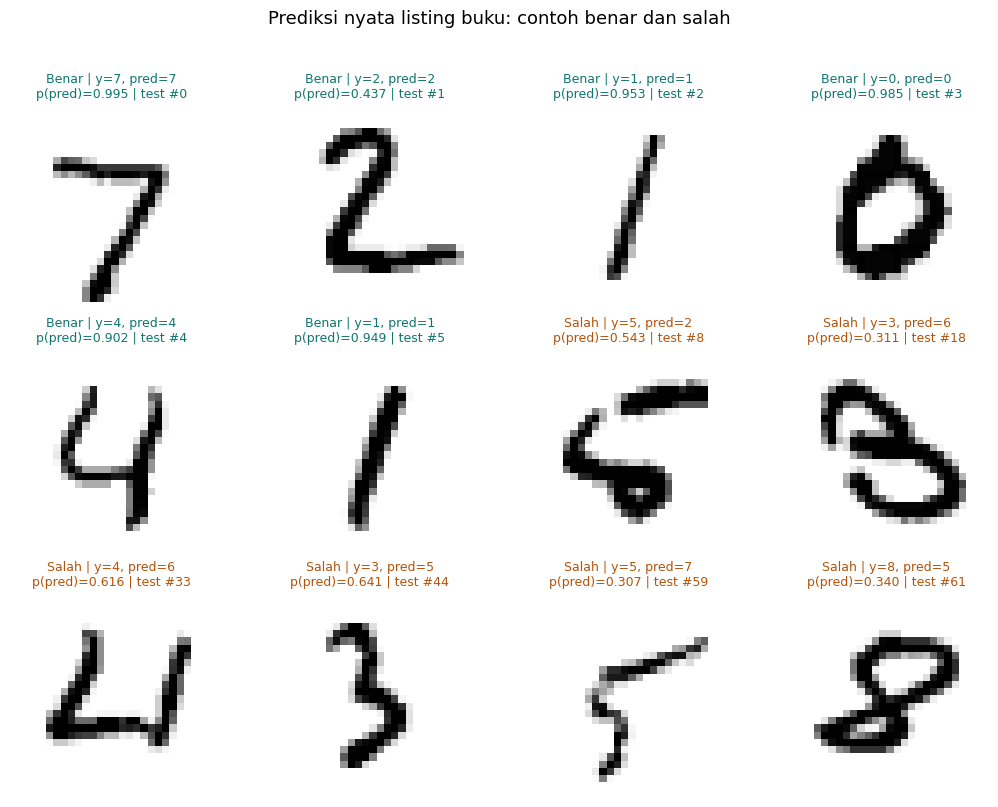

In [ ]:
# Grafik 7: enam benar pertama dan enam salah pertama, model listing buku.
correct_indices = np.flatnonzero(book_test_predictions == y_test)[:6]
incorrect_indices = np.flatnonzero(book_test_predictions != y_test)[:6]
example_indices = np.concatenate([correct_indices, incorrect_indices])
assert len(example_indices) == 12
fig, axes = plt.subplots(3, 4, figsize=(10.5, 8.2))
for ax, index in zip(axes.ravel(), example_indices):
    prediction, actual = int(book_test_predictions[index]), int(y_test[index])
    is_correct = prediction == actual
    confidence = float(book_test_probabilities[index, prediction])
    ax.imshow(x_test[index], cmap='gray_r', vmin=0, vmax=255)
    ax.set_title(f'{"Benar" if is_correct else "Salah"} | y={actual}, pred={prediction}\n'
                 f'p(pred)={confidence:.3f} | test #{index}', fontsize=9,
                 color='#0f766e' if is_correct else '#b45309')
    ax.axis('off')
fig.suptitle('Prediksi nyata listing buku: contoh benar dan salah', fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()